# Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
        

Levando em conta a base de dados _Dry Bean Dataset_, esta parte do Projeto Prático diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo feedforward multilayer perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Busca em Grade

Uma maneira padrão de escolher os parâmetros de um modelo de Machine Learning é por meio de uma busca em grade via força bruta. O algoritmo da busca em grade é dado como segue:

1. Escolha a métrica de desempenho que você deseja maximizar (por exemplo, o F-Score com média macro, adequado a um problema multiclasse com classes desbalanceadas)  
2. Escolha o algoritmo de Machine Learning (exemplo: redes neurais artificiais). Em seguida, defina os parâmetros ou hiperparâmetros deste tipo de modelo sobre os quais você deseja otimizar (número de épocas, taxa de aprendizado, etc.) e construa um array de valores a serem testados para cada parâmetro ou hiperparâmetro.  
3. Defina a grade de busca, a qual é dada como o produto cartesiano dos valores de cada parâmetro a ser testado. Por exemplo, para os arrays [50, 100, 1000] e [10, 15], tem-se que a grade é [(50,10), (50,15), (100,10), (100,15), (1000,10), (1000,15)].
4. Para cada combinação de parâmetros a serem otimizados, utilize _apenas o conjunto de treinamento_ para realizar uma validação cruzada (holdout ou k-fold) e calcule a métrica de avaliação nos conjuntos de validação gerados por ela. O conjunto de teste não participa da busca. Vamos efetuar validação cruzada holdout 70/30 estratificada.
5. Escolha a combinação de parâmetros que maximiza a métrica de avaliação na validação. Este é o modelo otimizado, que deve então ser reavaliado uma única vez no conjunto de teste.

Por que esta abordagem funciona? Porque a busca em grade efetua uma pesquisa extensiva sobre as possíveis combinações de valores para cada um dos parâmetros a serem ajustados. Para cada combinação, ela estima a performance do modelo em dados não utilizados no seu treinamento (os conjuntos de validação). Por fim, o modelo com melhor métrica de desempenho é escolhido. Tem-se então que este modelo é o que tem maior chance de generalizar bem mediante dados nunca antes vistos, e o conjunto de teste, que não foi utilizado na busca, fornece a estimativa final e não enviesada desse desempenho.

## Efetuando a Busca em Grade sobre Hiperparâmetros das Top-6 RNAs

Considerando a etapa anterior do projeto prático, foram identificadas pelo menos 6 melhores Redes Neurais para o problema da classificação multiclasse das variedades de feijão no conjunto de dados selecionado. Estas redes podem ter sido obtidas pela estratégia própria ou pela regra da Pirâmide Geométrica, e todas utilizam os 16 atributos numéricos como preditores.

A primeira etapa desta segunda parte do projeto consiste em trazer para este notebook estas seis arquiteturas, ressaltando:

1. Número de neurônios ocultos por camada  
2. Função de Ativação  
3. Estratégia de origem da arquitetura (Própria ou Pirâmide Geométrica)  
4. Desempenho médio ± desvio padrão nos testes anteriores  
5. Número de repetições que a equipe conseguiu realizar para verificar os resultados  

Elabore uma busca em grade sobre estas arquiteturas que contemple variações nos hiperparâmetros a seguir, conforme documentação de [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

A. Solver (não usar o LBFGS, pois é mais adequado para datasets pequenos)  
B. Batch Size  
C. Learning Rate Init  
D. Paciência 
E. Épocas  

Nesta busca em grade, contemple a utilização do objeto [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), com a métrica escolhida no parâmetro `scoring` (por exemplo, `'f1_macro'`) e a validação cruzada realizada apenas com o conjunto de treinamento (já escalonado conforme a estratégia da etapa anterior).

In [1]:
# Importação das bibliotecas necessárias
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score, classification_report
)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)


## Validação Cruzada k-fold

Na elaboração da busca em grade, vamos avaliar os modelos propostos segundo uma estratégia de validação cruzada ainda não explorada até o momento: a validação cruzada *k-fold*. Segundo a mesma, o conjunto de dados é particionado em *k* partes (*folds*): a cada iteração, separa-se uma das partes para validação e o modelo é treinado com as *k-1* partes remanescentes. Valores sugestivos de *k* na literatura são *k* = 3, 5 ou 10, pois o custo computacional desta validação dos modelos é alto. A métrica de desempenho é resultante da média dos desempenhos nas *k* iterações. A figura a seguir ilustra a ideia desta avaliação:

<img src="https://ethen8181.github.io/machine-learning/model_selection/img/kfolds.png" width="600">

Considerando a métrica de desempenho F1-Score (com média macro, dado que o problema possui 7 classes), considere a validação cruzada 5-fold estratificada para aferir os resultados da busca em grade anterior, realizada *apenas com o conjunto de treinamento*. O conjunto de teste deve ser utilizado uma única vez, para avaliar a melhor configuração encontrada.

## Preparação dos dados

A base é carregada diretamente do repositório UCI. Primeiro, separamos os dados em treino (70%) e teste (30%), mantendo a proporção das sete classes com `stratify` e a semente aleatória utilizada pela equipe (`random_state=42`).

**Cuidado metodológico:** o `StandardScaler` foi colocado dentro de um `Pipeline`. Assim, em cada fold, o escalonador é ajustado somente com a parcela usada para treinar aquele fold. Isso evita que as informações do fold de validação influenciem o pré-processamento. O conjunto de teste permanece separado durante toda a busca.


In [2]:
# Carregando a base Dry Bean Dataset (UCI ID = 602)
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features.copy()
y = dry_bean.data.targets["Class"].copy()

# Holdout estratificado: 70% para desenvolvimento e 30% para teste final
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print(f"Base completa:       X={X.shape}, y={y.shape}")
print(f"Treinamento:         X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Teste:               X_test={X_test.shape}, y_test={y_test.shape}")
print("\nDistribuição das classes no conjunto de treino:")
display(y_train.value_counts().sort_index().to_frame("Quantidade"))


Base completa:       X=(13611, 16), y=(13611,)
Treinamento:         X_train=(9527, 16), y_train=(9527,)
Teste:               X_test=(4084, 16), y_test=(4084,)

Distribuição das classes no conjunto de treino:


,Quantidade
Class,
BARBUNYA,925
BOMBAY,365
CALI,1141
DERMASON,2482
HOROZ,1350
SEKER,1419
SIRA,1845


In [3]:
# Top-6 arquiteturas distintas selecionadas da PP2.2.2 (3 da Estratégia Própria + 3 da Pirâmide Geométrica)
top6_arquiteturas = [
    {
        "ID": "RNA 1",
        "Camadas Ocultas": (32,),
        "Nº de Camadas": 1,
        "Função de Ativação": "relu",
        "Estratégia de Origem": "Pirâmide Geométrica (α = 3)",
        "F1-Score Anterior (Média ± DP)": "0.9435 ± 0.0041",
        "Acurácia Anterior (Média ± DP)": "0.9327 ± 0.0046",
        "Nº de Repetições": 10
    },
    {
        "ID": "RNA 2",
        "Camadas Ocultas": (30,),
        "Nº de Camadas": 1,
        "Função de Ativação": "relu",
        "Estratégia de Origem": "Estratégia Própria",
        "F1-Score Anterior (Média ± DP)": "0.9433 ± 0.0043",
        "Acurácia Anterior (Média ± DP)": "0.9323 ± 0.0048",
        "Nº de Repetições": 10
    },
    {
        "ID": "RNA 3",
        "Camadas Ocultas": (20, 12),
        "Nº de Camadas": 2,
        "Função de Ativação": "tanh",
        "Estratégia de Origem": "Pirâmide Geométrica (α = 3)",
        "F1-Score Anterior (Média ± DP)": "0.9426 ± 0.0044",
        "Acurácia Anterior (Média ± DP)": "0.9322 ± 0.0047",
        "Nº de Repetições": 10
    },
    {
        "ID": "RNA 4",
        "Camadas Ocultas": (30, 20),
        "Nº de Camadas": 2,
        "Função de Ativação": "relu",
        "Estratégia de Origem": "Estratégia Própria",
        "F1-Score Anterior (Média ± DP)": "0.9424 ± 0.0036",
        "Acurácia Anterior (Média ± DP)": "0.9315 ± 0.0041",
        "Nº de Repetições": 10
    },
    {
        "ID": "RNA 5",
        "Camadas Ocultas": (20, 10),
        "Nº de Camadas": 2,
        "Função de Ativação": "tanh",
        "Estratégia de Origem": "Estratégia Própria",
        "F1-Score Anterior (Média ± DP)": "0.9417 ± 0.0038",
        "Acurácia Anterior (Média ± DP)": "0.9310 ± 0.0042",
        "Nº de Repetições": 10
    },
    {
        "ID": "RNA 6",
        "Camadas Ocultas": (21,),
        "Nº de Camadas": 1,
        "Função de Ativação": "relu",
        "Estratégia de Origem": "Pirâmide Geométrica (α = 2)",
        "F1-Score Anterior (Média ± DP)": "0.9415 ± 0.0038",
        "Acurácia Anterior (Média ± DP)": "0.9306 ± 0.0040",
        "Nº de Repetições": 10
    }
]

df_top6 = pd.DataFrame(top6_arquiteturas)
display(df_top6)

,ID,Camadas Ocultas,Nº de Camadas,Função de Ativação,Estratégia de Origem,F1-Score Anterior (Média ± DP),Acurácia Anterior (Média ± DP),Nº de Repetições
0,RNA 1,"(32,)",1,relu,Pirâmide Geométrica (α = 3),0.9435 ± 0.0041,0.9327 ± 0.0046,10
1,RNA 2,"(30,)",1,relu,Estratégia Própria,0.9433 ± 0.0043,0.9323 ± 0.0048,10
2,RNA 3,"(20, 12)",2,tanh,Pirâmide Geométrica (α = 3),0.9426 ± 0.0044,0.9322 ± 0.0047,10
3,RNA 4,"(30, 20)",2,relu,Estratégia Própria,0.9424 ± 0.0036,0.9315 ± 0.0041,10
4,RNA 5,"(20, 10)",2,tanh,Estratégia Própria,0.9417 ± 0.0038,0.9310 ± 0.0042,10
5,RNA 6,"(21,)",1,relu,Pirâmide Geométrica (α = 2),0.9415 ± 0.0038,0.9306 ± 0.0040,10


## Configuração da busca em grade

Cada uma das seis arquiteturas mantém a quantidade de camadas ocultas e sua função de ativação definidas na PP2.2.2. A busca otimiza os cinco hiperparâmetros solicitados: `solver`, `batch_size`, `learning_rate_init`, `n_iter_no_change` e `max_iter`.

São 32 combinações por arquitetura (2 × 2 × 2 × 2 × 2), totalizando 192 configurações. Com validação cruzada estratificada 5-fold, serão realizados 960 ajustes de modelos. O `GridSearchCV` seleciona a configuração pela média do F1-Score macro nos folds.


In [4]:
# Validação cruzada estratificada 5-fold
cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hiperparâmetros a serem otimizados
grade_parametros_base = {
    "mlp__solver": ["adam", "sgd"],
    "mlp__batch_size": [64, 200],
    "mlp__learning_rate_init": [0.001, 0.01],
    "mlp__n_iter_no_change": [10, 20],
    "mlp__max_iter": [150, 250]
}

# Cada dicionário mantém a arquitetura e a ativação pareadas corretamente
param_grid = [
    {
        "mlp__hidden_layer_sizes": [arq["Camadas Ocultas"]],
        "mlp__activation": [arq["Função de Ativação"]],
        **grade_parametros_base
    }
    for arq in top6_arquiteturas
]

# O scaler é ajustado novamente dentro de cada fold, sem vazamento de dados
pipeline_busca = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(random_state=42))
])

grid_search = GridSearchCV(
    estimator=pipeline_busca,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_5fold,
    n_jobs=-1,
    refit=True,
    verbose=2,
    return_train_score=False
)

print("Quantidade de configurações:", sum(
    np.prod([len(v) for v in grade.values()]) for grade in param_grid
))
print("Quantidade de ajustes considerando 5 folds:", 192 * 5)

# A busca utiliza SOMENTE o conjunto de treinamento
grid_search.fit(X_train, y_train)

print("\nMelhor F1-Score macro médio na validação:", grid_search.best_score_)
print("Melhores hiperparâmetros:")
display(pd.Series(grid_search.best_params_, name="Valor").to_frame())


Quantidade de configurações: 192
Quantidade de ajustes considerando 5 folds: 960
Fitting 5 folds for each of 192 candidates, totalling 960 fits

Melhor F1-Score macro médio na validação: 0.9449918935477651
Melhores hiperparâmetros:


,Valor
mlp__activation,relu
mlp__batch_size,64
mlp__hidden_layer_sizes,"(30, 20)"
mlp__learning_rate_init,0.001
mlp__max_iter,250
mlp__n_iter_no_change,10
mlp__solver,adam


In [5]:
# Organizando o resultado de todas as configurações testadas
resultados_grid = pd.DataFrame(grid_search.cv_results_)

colunas_resultado = [
    "param_mlp__hidden_layer_sizes",
    "param_mlp__activation",
    "param_mlp__solver",
    "param_mlp__batch_size",
    "param_mlp__learning_rate_init",
    "param_mlp__n_iter_no_change",
    "param_mlp__max_iter",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabela_grid = resultados_grid[colunas_resultado].copy()
tabela_grid = tabela_grid.sort_values(
    by=["rank_test_score", "mean_test_score"],
    ascending=[True, False]
).reset_index(drop=True)

tabela_grid = tabela_grid.rename(columns={
    "param_mlp__hidden_layer_sizes": "Camadas ocultas",
    "param_mlp__activation": "Ativação",
    "param_mlp__solver": "Solver",
    "param_mlp__batch_size": "Batch size",
    "param_mlp__learning_rate_init": "Learning rate inicial",
    "param_mlp__n_iter_no_change": "Paciência",
    "param_mlp__max_iter": "Épocas máximas",
    "mean_test_score": "F1 macro médio",
    "std_test_score": "Desvio padrão",
    "rank_test_score": "Posição"
})

print("Dez melhores configurações na validação cruzada:")
display(tabela_grid.head(10).style.format({
    "F1 macro médio": "{:.4f}",
    "Desvio padrão": "{:.4f}"
}))


Dez melhores configurações na validação cruzada:


,Camadas ocultas,Ativação,Solver,Batch size,Learning rate inicial,Paciência,Épocas máximas,F1 macro médio,Desvio padrão,Posição
0,"(30, 20)",relu,adam,64,0.001000,10,250,0.9450,0.0053,1
1,"(30,)",relu,sgd,64,0.010000,20,250,0.9449,0.0046,2
2,"(30, 20)",relu,adam,200,0.001000,20,250,0.9447,0.0045,3
3,"(32,)",relu,sgd,64,0.010000,20,150,0.9445,0.0043,4
4,"(32,)",relu,adam,200,0.010000,20,150,0.9445,0.0043,5
5,"(32,)",relu,adam,200,0.010000,10,150,0.9443,0.0023,6
6,"(32,)",relu,adam,200,0.010000,10,250,0.9443,0.0023,6
7,"(32,)",relu,sgd,64,0.010000,20,250,0.9443,0.0036,8
8,"(20, 12)",tanh,sgd,200,0.010000,20,250,0.9442,0.0036,9
9,"(32,)",relu,adam,64,0.001000,10,250,0.9442,0.0051,10


## Identificando a mellhor solução

Como resultado da busca em grade com validação cruzada 5-fold, identifique o modelo otimizado com melhor desempenho para o problema. Apresente claramente este modelo, sua arquitetura (número de camadas ocultas, neurônios por camada e função de ativação), os hiperparâmetros otimizados (solver, batch size, taxa de aprendizado inicial, paciência e épocas) e os resultados (F1-Score macro) para cada um dos folds avaliados, junto com a média ± desvio padrão entre os folds. Em seguida, reavalie este modelo uma única vez no conjunto de teste, apresentando a matriz de confusão, a acurácia e o F1-Score macro. Esta é a melhor solução identificada em decorrência deste projeto.

Melhor arquitetura e hiperparâmetros:
  activation: relu
  batch_size: 64
  hidden_layer_sizes: (30, 20)
  learning_rate_init: 0.001
  max_iter: 250
  n_iter_no_change: 10
  solver: adam

F1-Score macro em cada fold:
  Fold 1: 0.9426
  Fold 2: 0.9367
  Fold 3: 0.9482
  Fold 4: 0.9451
  Fold 5: 0.9524

Média do F1-Score macro: 0.9450
Desvio padrão amostral:   0.0059

=== Avaliação final no conjunto de teste ===
Acurácia:       0.9248
F1-Score macro: 0.9365

Relatório de classificação:
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.91      0.93       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.94      0.94      0.94       489
    DERMASON       0.91      0.92      0.91      1064
       HOROZ       0.95      0.97      0.96       578
       SEKER       0.93      0.96      0.94       608
        SIRA       0.88      0.86      0.87       791

    accuracy                           0.92      4084
   macro avg       0.94

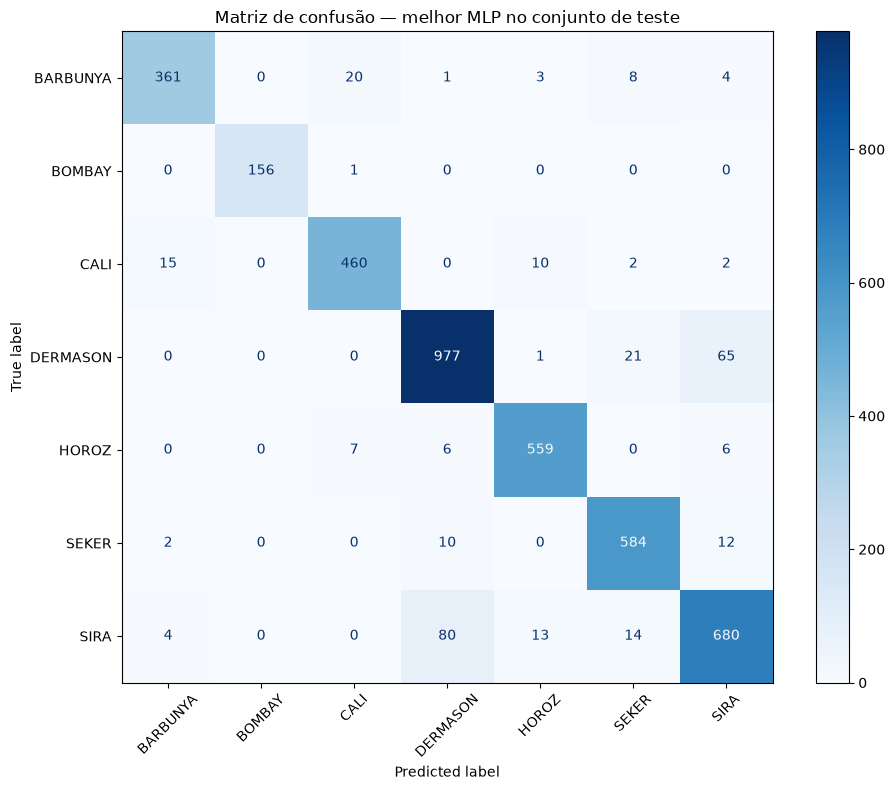

In [6]:
# Recuperando os resultados individuais dos cinco folds para a melhor configuração
indice_melhor = grid_search.best_index_
f1_folds = np.array([
    grid_search.cv_results_[f"split{i}_test_score"][indice_melhor]
    for i in range(5)
])

print("Melhor arquitetura e hiperparâmetros:")
melhores_parametros = grid_search.best_params_
for parametro, valor in melhores_parametros.items():
    print(f"  {parametro.replace('mlp__', '')}: {valor}")

print("\nF1-Score macro em cada fold:")
for i, valor in enumerate(f1_folds, start=1):
    print(f"  Fold {i}: {valor:.4f}")

print(f"\nMédia do F1-Score macro: {f1_folds.mean():.4f}")
print(f"Desvio padrão amostral:   {f1_folds.std(ddof=1):.4f}")

# O GridSearchCV com refit=True já reajustou o melhor Pipeline em todo X_train.
# Agora o conjunto de teste é utilizado uma única vez para avaliação final.
melhor_modelo = grid_search.best_estimator_
y_pred = melhor_modelo.predict(X_test)

acuracia_teste = accuracy_score(y_test, y_pred)
f1_teste = f1_score(y_test, y_pred, average="macro")

print("\n=== Avaliação final no conjunto de teste ===")
print(f"Acurácia:       {acuracia_teste:.4f}")
print(f"F1-Score macro: {f1_teste:.4f}")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred, zero_division=0))

classes = melhor_modelo.named_steps["mlp"].classes_
cm = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
ax.set_title("Matriz de confusão — melhor MLP no conjunto de teste")
plt.tight_layout()
plt.show()


## Empacotando a solução

Suponha que você deve entregar este classificador a uma cooperativa ou órgão responsável pelo controle de qualidade e classificação de grãos de feijão seco. Para tanto, você deve fazer uma preparação do mesmo para utilização neste cenário. Uma vez que já identificou os melhores hiperparâmetros, o passo remanescente consiste em treinar o modelo com estes valores e todos os dados disponíveis, salvando o modelo treinado (pesos da rede e o escalonador dos atributos) ao final para entrega ao cliente. Assim, finalize o projeto prático realizando tais passos.

1. Consulte a documentação a seguir:
https://scikit-learn.org/stable/modules/model_persistence.html  
2. Treine o modelo com todos os dados, utilizando a arquitetura e os hiperparâmetros otimizados. O escalonador (`StandardScaler`) deve ser ajustado com todos os dados e salvo junto com a rede, preferencialmente em um único `Pipeline`  
3. Salve o modelo em disco  
4. Construa uma rotina que recupere o modelo em disco  
5. Mostre que a rotina é funcional, fazendo previsões com todos os elementos do dataset e exibindo uma matriz de confusão das mesmas. Como o modelo foi treinado com todos os dados, esta matriz serve apenas para verificar o funcionamento da rotina e não como estimativa de desempenho, que é dada pelos resultados da validação cruzada e do conjunto de teste

## Treinamento final e empacotamento

Após avaliar a melhor configuração no conjunto de teste, treinamos um novo Pipeline com todos os dados disponíveis. O `StandardScaler` é ajustado em todos os atributos e a MLP é treinada com os hiperparâmetros selecionados pela busca.

O arquivo salvo contém o pré-processamento e a rede neural juntos. A matriz de confusão calculada após recarregar esse modelo e prever a própria base completa serve somente para verificar o funcionamento do artefato; ela não representa uma estimativa imparcial de generalização.


In [7]:
# Pipeline final: scaler + MLP com os hiperparâmetros encontrados
modelo_final = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        random_state=42,
        hidden_layer_sizes=melhores_parametros["mlp__hidden_layer_sizes"],
        activation=melhores_parametros["mlp__activation"],
        solver=melhores_parametros["mlp__solver"],
        batch_size=melhores_parametros["mlp__batch_size"],
        learning_rate_init=melhores_parametros["mlp__learning_rate_init"],
        n_iter_no_change=melhores_parametros["mlp__n_iter_no_change"],
        max_iter=melhores_parametros["mlp__max_iter"]
    ))
])

# Treinando com todos os dados disponíveis
modelo_final.fit(X, y)

# Salvando o Pipeline completo em um único arquivo
nome_arquivo = "classificador_dry_beans.joblib"
joblib.dump(modelo_final, nome_arquivo)
print(f"Modelo salvo em: {nome_arquivo}")


Modelo salvo em: classificador_dry_beans.joblib


Quantidade de previsões realizadas: 13611
Acurácia na própria base (apenas verificação de funcionamento): 0.9387
F1 macro na própria base (apenas verificação de funcionamento): 0.9488


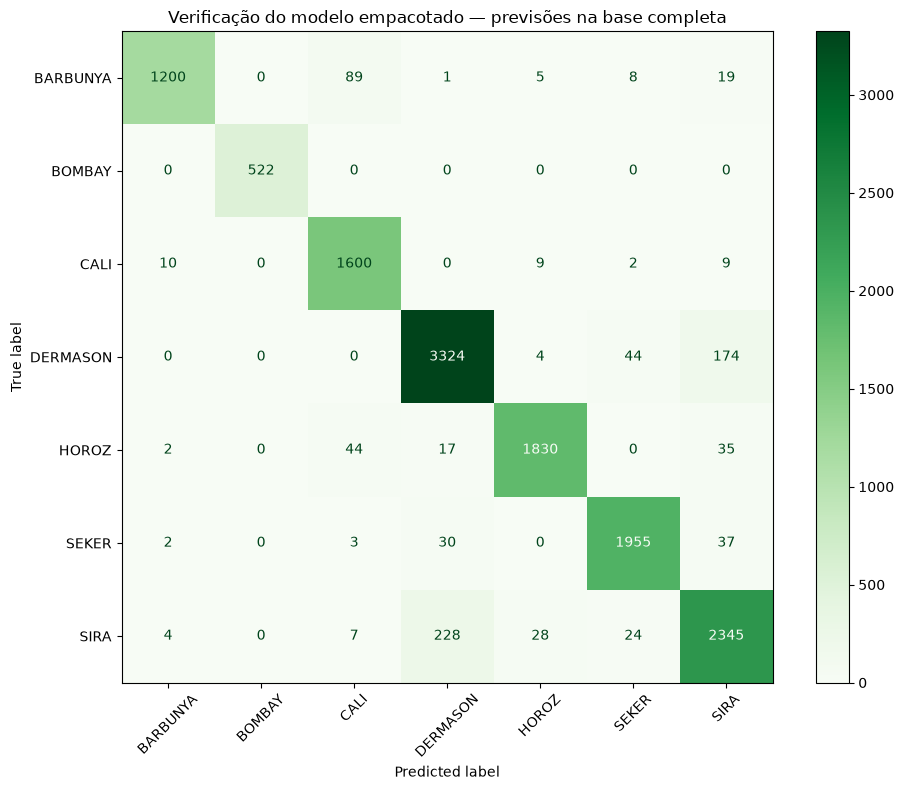

In [8]:
# Recuperando o modelo salvo em disco
modelo_carregado = joblib.load("classificador_dry_beans.joblib")

# Verificando a rotina de inferência com todas as amostras
previsoes_completas = modelo_carregado.predict(X)

print("Quantidade de previsões realizadas:", len(previsoes_completas))
print("Acurácia na própria base (apenas verificação de funcionamento):",
      f"{accuracy_score(y, previsoes_completas):.4f}")
print("F1 macro na própria base (apenas verificação de funcionamento):",
      f"{f1_score(y, previsoes_completas, average='macro'):.4f}")

cm_completa = confusion_matrix(
    y, previsoes_completas,
    labels=modelo_carregado.named_steps["mlp"].classes_
)
disp_completa = ConfusionMatrixDisplay(
    confusion_matrix=cm_completa,
    display_labels=modelo_carregado.named_steps["mlp"].classes_
)
fig, ax = plt.subplots(figsize=(10, 8))
disp_completa.plot(ax=ax, cmap="Greens", xticks_rotation=45, values_format="d")
ax.set_title("Verificação do modelo empacotado — previsões na base completa")
plt.tight_layout()
plt.show()


## Considerações finais

Nesta etapa do projeto, foi realizada a otimização de seis arquiteturas de redes neurais artificiais do tipo *Multilayer Perceptron* (MLP), previamente selecionadas na PP2.2.2. Para isso, foi utilizada uma busca em grade (*GridSearchCV*), considerando cinco hiperparâmetros: `solver`, `batch_size`, `learning_rate_init`, `n_iter_no_change` e `max_iter`. A combinação das alternativas resultou em 192 configurações, avaliadas por validação cruzada estratificada com cinco folds, totalizando 960 ajustes de modelos.

A melhor configuração encontrada correspondeu à **RNA 4**, com duas camadas ocultas contendo 30 e 20 neurônios, respectivamente, e função de ativação ReLU. Os hiperparâmetros selecionados foram: otimizador Adam, *batch size* de 64, taxa de aprendizado inicial de 0,001, paciência (`n_iter_no_change`) de 10 e limite máximo de 250 épocas (`max_iter`).

Na validação cruzada, os valores de F1-Score macro obtidos foram 0,9426, 0,9367, 0,9482, 0,9451 e 0,9524 nos cinco folds, respectivamente. A média foi de **0,9450**, com desvio padrão amostral de **0,0059**. A proximidade entre os resultados dos folds indica que o desempenho da configuração selecionada foi relativamente consistente nas diferentes partições do conjunto de treinamento.

Após a seleção dos hiperparâmetros, o modelo foi avaliado uma única vez no conjunto de teste, composto por 4.084 amostras. Nessa avaliação, obteve **acurácia de 0,9248 (92,48%)** e **F1-Score macro de 0,9365 (93,65%)**. Considerando o desempenho por classe, BOMBAY apresentou o melhor resultado, com F1-Score de 1,00, enquanto SIRA apresentou o menor, com 0,87. A matriz de confusão também evidenciou confusões entre SIRA e DERMASON, indicando que essas duas variedades foram mais difíceis de distinguir pelo classificador.

Por fim, a melhor configuração foi utilizada para treinar um novo Pipeline com todos os 13.611 registros disponíveis. O Pipeline reúne o `StandardScaler` e o classificador MLP, e foi salvo no arquivo `classificador_dry_beans.joblib`. Após o salvamento, o arquivo foi carregado novamente e utilizado para realizar previsões sobre todas as amostras do dataset, confirmando o funcionamento da rotina de persistência e inferência.

Nessa verificação com a base completa, foram realizadas 13.611 previsões, com acurácia de 0,9387 e F1-Score macro de 0,9488. Esses dois últimos valores não devem ser interpretados como estimativas de desempenho em dados desconhecidos, pois o modelo utilizado nessa etapa foi treinado com os próprios registros avaliados. Portanto, a avaliação de generalização do classificador deve ser representada pelos resultados da validação cruzada e, principalmente, pela avaliação independente no conjunto de teste.

Dessa forma, a PP2.2.3 concluiu a otimização das arquiteturas selecionadas, a avaliação da melhor configuração e a preparação do classificador para utilização posterior, mantendo o pré-processamento e a rede neural reunidos em um único artefato.